<a href="https://colab.research.google.com/github/uranovnass/resume/blob/main/ml10all.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.datasets import make_moons

from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True

In [3]:
PATH = "/content/sample_data/customers.csv"

df = pd.read_csv(PATH)

print("Размер датасета:", df.shape)
display(df.head())

Размер датасета: (600, 5)


,client_id,avg_check,purchases_month,days_since_last,discount_share
0,1,862,7.5,7,0.73
1,2,1995,0.8,80,0.32
2,3,2898,5.1,4,0.09
3,4,1017,9.6,10,0.64
4,5,715,9.2,7,0.68


In [4]:
print("Названия столбцов:")
print(df.columns.tolist())

print("\nТипы данных:")
print(df.dtypes)

print("\nКоличество пропусков:")
print(df.isnull().sum())

print("\nКоличество дубликатов:")
print(df.duplicated().sum())

Названия столбцов:
['client_id', 'avg_check', 'purchases_month', 'days_since_last', 'discount_share']

Типы данных:
client_id            int64
avg_check            int64
purchases_month    float64
days_since_last      int64
discount_share     float64
dtype: object

Количество пропусков:
client_id          0
avg_check          0
purchases_month    0
days_since_last    0
discount_share     0
dtype: int64

Количество дубликатов:
0


In [5]:
display(df.describe())

,client_id,avg_check,purchases_month,days_since_last,discount_share
count,600.000000,600.000000,600.000000,600.000000,600.000000
mean,300.500000,2573.296667,3.716333,35.523333,0.361817
std,173.349358,2010.384812,3.039698,38.379436,0.212241
min,1.000000,307.000000,0.100000,0.000000,0.000000
25%,150.750000,960.500000,0.900000,6.000000,0.180000
50%,300.500000,1529.500000,2.000000,18.000000,0.350000
75%,450.250000,4749.250000,6.600000,67.250000,0.560000
max,600.000000,7270.000000,10.100000,149.000000,0.890000


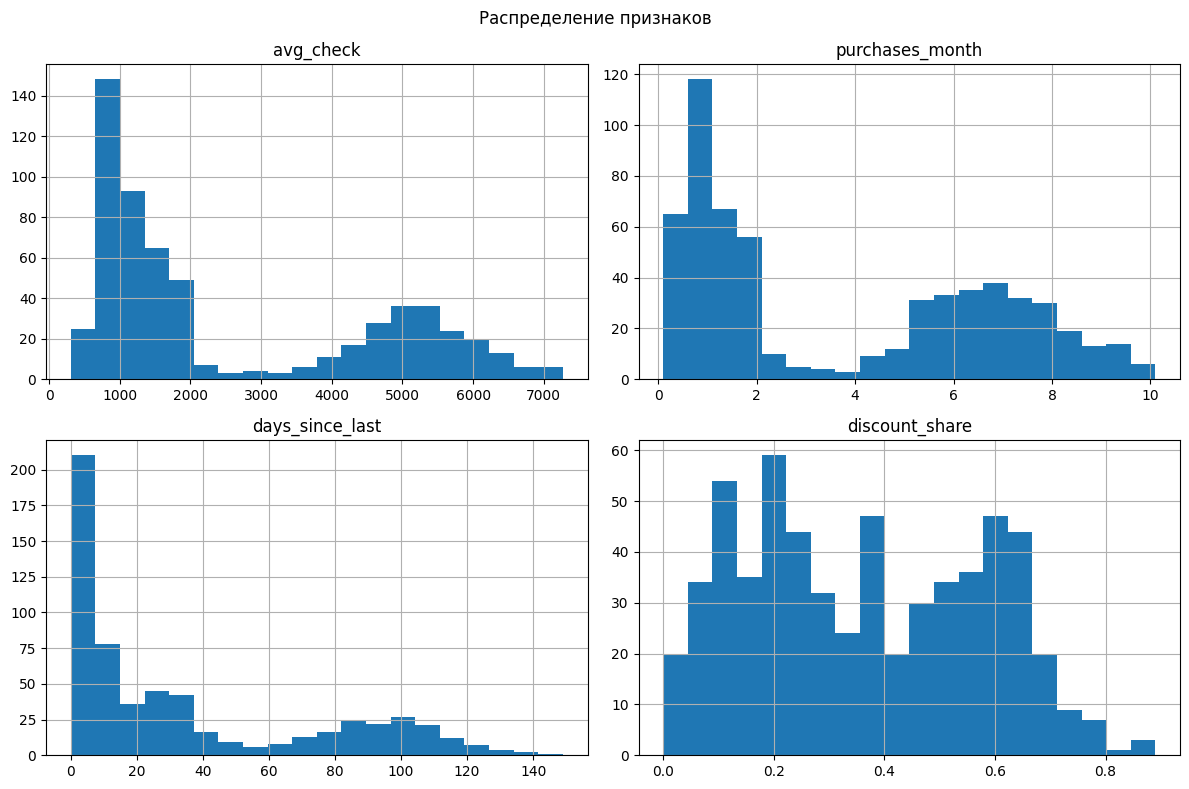

In [6]:
features = [
    "avg_check",
    "purchases_month",
    "days_since_last",
    "discount_share"
]

df[features].hist(figsize=(12, 8), bins=20)
plt.suptitle("Распределение признаков")
plt.tight_layout()
plt.show()

In [7]:
X = df[features].copy()

print("Признаки для кластеризации:")
display(X.head())

Признаки для кластеризации:


,avg_check,purchases_month,days_since_last,discount_share
0,862,7.5,7,0.73
1,1995,0.8,80,0.32
2,2898,5.1,4,0.09
3,1017,9.6,10,0.64
4,715,9.2,7,0.68


In [8]:
if X.isnull().sum().sum() > 0:
    X = X.fillna(X.median())

print("Пропуски после обработки:")
print(X.isnull().sum())

Пропуски после обработки:
avg_check          0
purchases_month    0
days_since_last    0
discount_share     0
dtype: int64


In [9]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features
)

display(X_scaled.head())

,avg_check,purchases_month,days_since_last,discount_share
0,-0.851939,1.245789,-0.743813,1.736189
1,-0.287895,-0.960216,1.159834,-0.197189
2,0.161648,0.455578,-0.822045,-1.281766
3,-0.774775,1.937224,-0.665581,1.311789
4,-0.925120,1.805522,-0.743813,1.500411


In [10]:
print("Средние значения после масштабирования:")
print(X_scaled.mean())

print("\nСтандартные отклонения:")
print(X_scaled.std())

Средние значения после масштабирования:
avg_check          2.072416e-17
purchases_month   -2.368476e-17
days_since_last   -2.368476e-17
discount_share    -4.440892e-17
dtype: float64

Стандартные отклонения:
avg_check          1.000834
purchases_month    1.000834
days_since_last    1.000834
discount_share     1.000834
dtype: float64


In [11]:
k_a = 4

kmeans_a = KMeans(
    n_clusters=k_a,
    random_state=42,
    n_init=10
)

clusters_a = kmeans_a.fit_predict(X_scaled)

df["cluster_A"] = clusters_a

print("Количество объектов в каждом кластере:")
print(df["cluster_A"].value_counts().sort_index())

Количество объектов в каждом кластере:
cluster_A
0     59
1    220
2    170
3    151
Name: count, dtype: int64


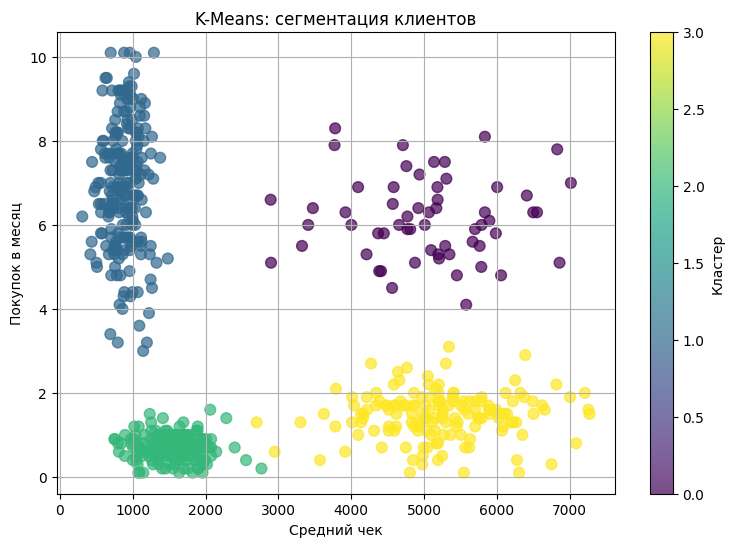

In [12]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["avg_check"],
    df["purchases_month"],
    c=df["cluster_A"],
    cmap="viridis",
    s=60,
    alpha=0.7
)

plt.xlabel("Средний чек")
plt.ylabel("Покупок в месяц")
plt.title("K-Means: сегментация клиентов")

plt.colorbar(label="Кластер")
plt.show()

In [13]:
cluster_profile_a = df.groupby("cluster_A")[features].mean()

display(cluster_profile_a.round(2))

,avg_check,purchases_month,days_since_last,discount_share
cluster_A,,,,
0,5037.63,6.15,3.78,0.09
1,884.42,6.94,6.14,0.59
2,1543.98,0.70,91.95,0.33
3,5229.86,1.47,27.21,0.16


In [14]:
cluster_sizes_a = df["cluster_A"].value_counts().sort_index()

print("Размеры кластеров:")
display(cluster_sizes_a)

Размеры кластеров:


,count
cluster_A,
0,59
1,220
2,170
3,151


In [15]:
cluster_share_a = (
    df["cluster_A"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("Доля клиентов в каждом кластере (%):")
display(cluster_share_a.round(2))

Доля клиентов в каждом кластере (%):


,proportion
cluster_A,
0,9.83
1,36.67
2,28.33
3,25.17


In [16]:
profile_scaled_a = df.groupby("cluster_A")[features].mean()

profile_scaled_a = scaler.transform(profile_scaled_a)

profile_scaled_a = pd.DataFrame(
    profile_scaled_a,
    columns=features
)

profile_scaled_a.index = sorted(df["cluster_A"].unique())

display(profile_scaled_a.round(2))

,avg_check,purchases_month,days_since_last,discount_share
0,1.23,0.80,-0.83,-1.28
1,-0.84,1.06,-0.77,1.10
2,-0.51,-0.99,1.47,-0.13
3,1.32,-0.74,-0.22,-0.95


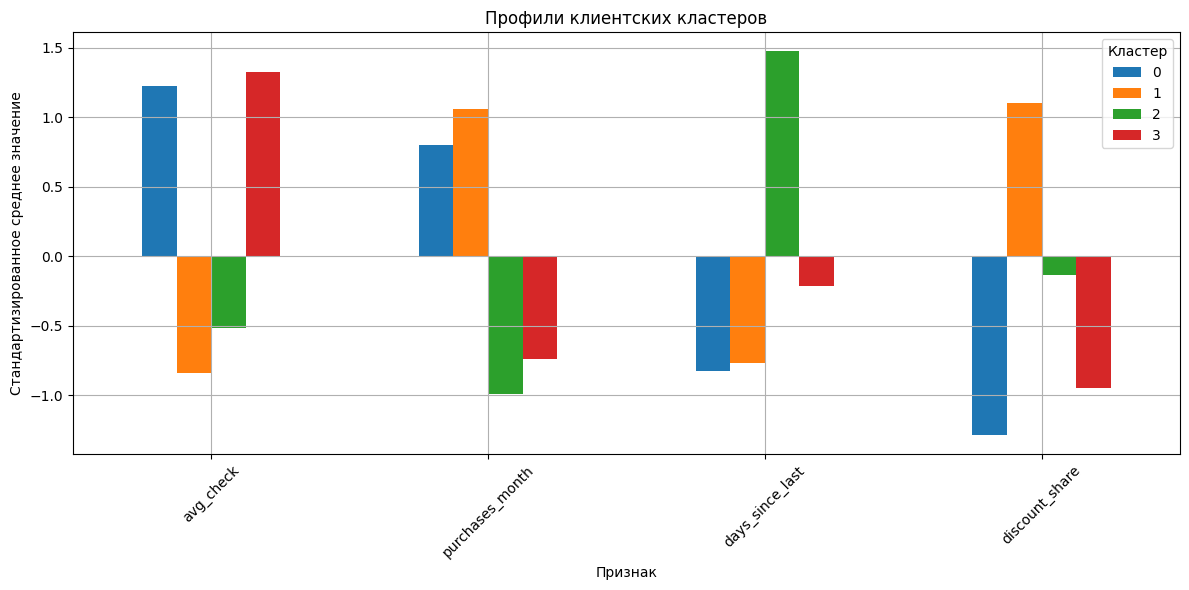

In [17]:
profile_scaled_a.T.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Профили клиентских кластеров")
plt.xlabel("Признак")
plt.ylabel("Стандартизированное среднее значение")
plt.xticks(rotation=45)
plt.legend(title="Кластер")
plt.tight_layout()
plt.show()

In [18]:
silhouette_a = silhouette_score(
    X_scaled,
    df["cluster_A"]
)

print(f"Silhouette Score для A: {silhouette_a:.4f}")

Silhouette Score для A: 0.6524


В варианте A была выполнена сегментация клиентов методом K-Means на 4 кластера. Перед кластеризацией признаки были стандартизированы, что позволило избежать доминирования признаков с большим числовым диапазоном. Для каждого кластера были рассчитаны средние значения исходных признаков. Это позволило интерпретировать полученные группы как различные типы клиентов по величине среднего чека, частоте покупок, давности последней покупки и использованию скидок.

In [19]:
inertias = []

k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertias.append(model.inertia_)

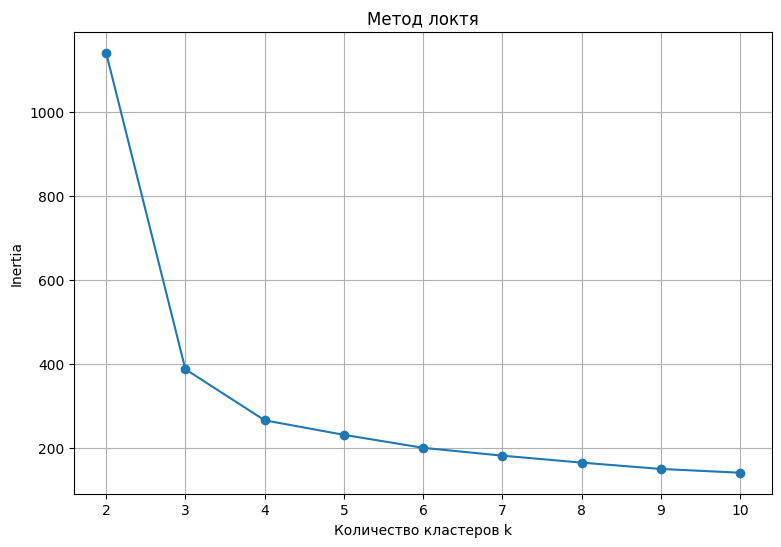

In [20]:
plt.figure(figsize=(9, 6))

plt.plot(
    list(k_values),
    inertias,
    marker="o"
)

plt.xlabel("Количество кластеров k")
plt.ylabel("Inertia")
plt.title("Метод локтя")

plt.xticks(list(k_values))
plt.show()

In [22]:
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

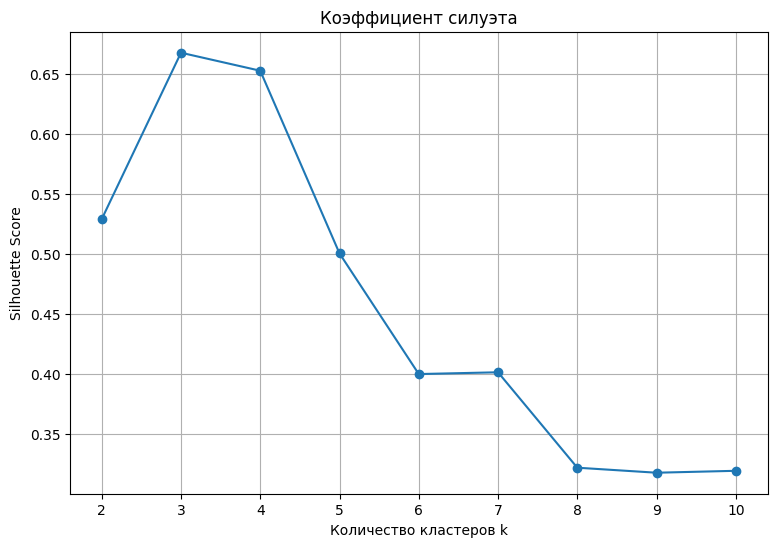

In [23]:
plt.figure(figsize=(9, 6))

plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Количество кластеров k")
plt.ylabel("Silhouette Score")
plt.title("Коэффициент силуэта")

plt.xticks(list(k_values))
plt.show()

In [24]:
results_b = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertias,
    "silhouette": silhouette_scores
})

display(results_b.round(4))

,k,inertia,silhouette
0,2,1140.9779,0.5288
1,3,387.0439,0.6674
2,4,265.4097,0.6524
3,5,230.7792,0.5002
4,6,199.8690,0.3997
5,7,181.1437,0.4012
6,8,164.5462,0.3217
7,9,149.4813,0.3176
8,10,140.5166,0.3192


In [25]:
best_k_silhouette = results_b.loc[
    results_b["silhouette"].idxmax(),
    "k"
]

best_score = results_b["silhouette"].max()

print(f"Лучшее k по silhouette: {best_k_silhouette}")
print(f"Silhouette Score: {best_score:.4f}")

Лучшее k по silhouette: 3
Silhouette Score: 0.6674


In [26]:
k_b = int(best_k_silhouette)

print("Итоговое количество кластеров:", k_b)

Итоговое количество кластеров: 3


In [27]:
kmeans_b = KMeans(
    n_clusters=k_b,
    random_state=42,
    n_init=10
)

df["cluster_B"] = kmeans_b.fit_predict(X_scaled)

print("Размеры кластеров:")
print(df["cluster_B"].value_counts().sort_index())

Размеры кластеров:
cluster_B
0    210
1    220
2    170
Name: count, dtype: int64


In [28]:
cluster_profile_b = df.groupby("cluster_B")[features].mean()

display(cluster_profile_b.round(2))

,avg_check,purchases_month,days_since_last,discount_share
cluster_B,,,,
0,5175.85,2.78,20.62,0.14
1,884.42,6.94,6.14,0.59
2,1543.98,0.70,91.95,0.33


In [29]:
profile_b_scaled = df.groupby("cluster_B")[features].mean()

profile_b_scaled = pd.DataFrame(
    StandardScaler().fit_transform(profile_b_scaled),
    columns=features
)

profile_b_scaled.index = sorted(df["cluster_B"].unique())

display(profile_b_scaled.round(2))

,avg_check,purchases_month,days_since_last,discount_share
0,1.40,-0.27,-0.51,-1.16
1,-0.87,1.34,-0.89,1.28
2,-0.53,-1.07,1.40,-0.12


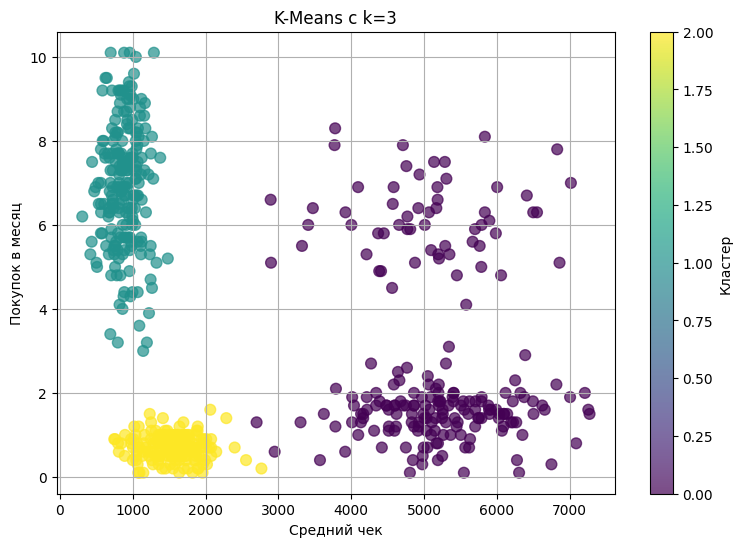

In [30]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["avg_check"],
    df["purchases_month"],
    c=df["cluster_B"],
    cmap="viridis",
    s=60,
    alpha=0.7
)

plt.xlabel("Средний чек")
plt.ylabel("Покупок в месяц")
plt.title(f"K-Means с k={k_b}")

plt.colorbar(label="Кластер")
plt.show()

In [31]:
silhouette_b = silhouette_score(
    X_scaled,
    df["cluster_B"]
)

davies_bouldin_b = davies_bouldin_score(
    X_scaled,
    df["cluster_B"]
)

calinski_b = calinski_harabasz_score(
    X_scaled,
    df["cluster_B"]
)

print(f"Silhouette Score: {silhouette_b:.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin_b:.4f}")
print(f"Calinski-Harabasz Score: {calinski_b:.4f}")

Silhouette Score: 0.6674
Davies-Bouldin Index: 0.5175
Calinski-Harabasz Score: 1552.4530


In [32]:
kmeans_b_123 = KMeans(
    n_clusters=k_b,
    random_state=123,
    n_init=10
)

clusters_b_123 = kmeans_b_123.fit_predict(X_scaled)

print("Размеры кластеров при random_state=42:")
print(df["cluster_B"].value_counts().sort_index())

print("\nРазмеры кластеров при random_state=123:")
print(pd.Series(clusters_b_123).value_counts().sort_index())

Размеры кластеров при random_state=42:
cluster_B
0    210
1    220
2    170
Name: count, dtype: int64

Размеры кластеров при random_state=123:
0    170
1    210
2    220
Name: count, dtype: int64


In [33]:
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(
    df["cluster_B"],
    clusters_b_123
)

print(f"Adjusted Rand Index: {ari:.4f}")

Adjusted Rand Index: 1.0000


Для выбора количества кластеров были использованы метод локтя и коэффициент силуэта. Метод локтя позволил определить область, в которой дальнейшее увеличение количества кластеров перестаёт существенно уменьшать внутрикластерную ошибку. Коэффициент силуэта позволил оценить разделимость кластеров. Итоговое значение k было выбрано с учётом обоих критериев. После выбора k были построены профили кластеров и выполнена их содержательная интерпретация. Дополнительно кластеризация была повторена с другим значением random_state. Устойчивость результата оценивалась с помощью Adjusted Rand Index.

In [34]:
X_c, y_true_c = make_moons(
    n_samples=500,
    noise=0.08,
    random_state=42
)

print("Размер данных:", X_c.shape)

Размер данных: (500, 2)


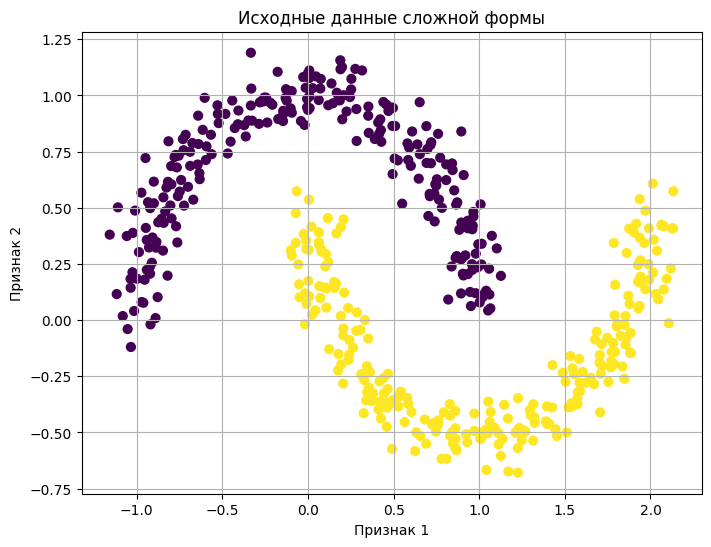

In [35]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_c[:, 0],
    X_c[:, 1],
    c=y_true_c,
    cmap="viridis",
    s=40
)

plt.xlabel("Признак 1")
plt.ylabel("Признак 2")
plt.title("Исходные данные сложной формы")

plt.show()

In [36]:
scaler_c = StandardScaler()

X_c_scaled = scaler_c.fit_transform(X_c)

print("Масштабирование выполнено.")

Масштабирование выполнено.


In [37]:
kmeans_c = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels_kmeans_c = kmeans_c.fit_predict(X_c_scaled)

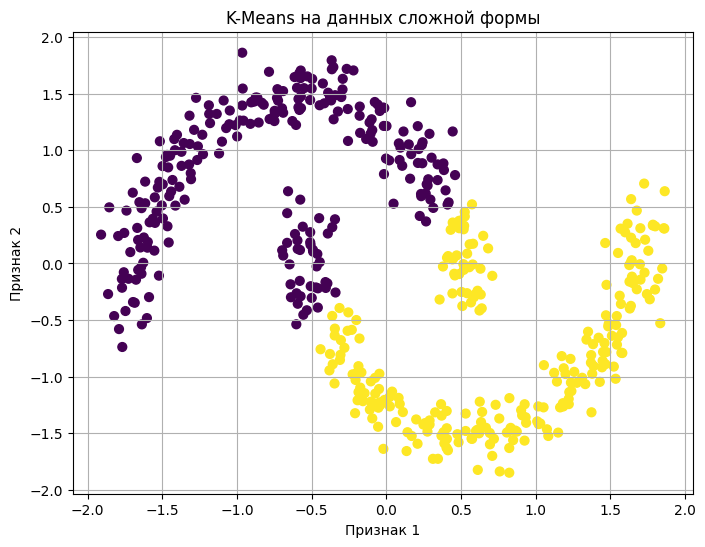

In [38]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_c_scaled[:, 0],
    X_c_scaled[:, 1],
    c=labels_kmeans_c,
    cmap="viridis",
    s=40
)

plt.xlabel("Признак 1")
plt.ylabel("Признак 2")
plt.title("K-Means на данных сложной формы")

plt.show()

In [39]:
sil_kmeans_c = silhouette_score(
    X_c_scaled,
    labels_kmeans_c
)

db_kmeans_c = davies_bouldin_score(
    X_c_scaled,
    labels_kmeans_c
)

print(f"Silhouette: {sil_kmeans_c:.4f}")
print(f"Davies-Bouldin: {db_kmeans_c:.4f}")

Silhouette: 0.4932
Davies-Bouldin: 0.8132


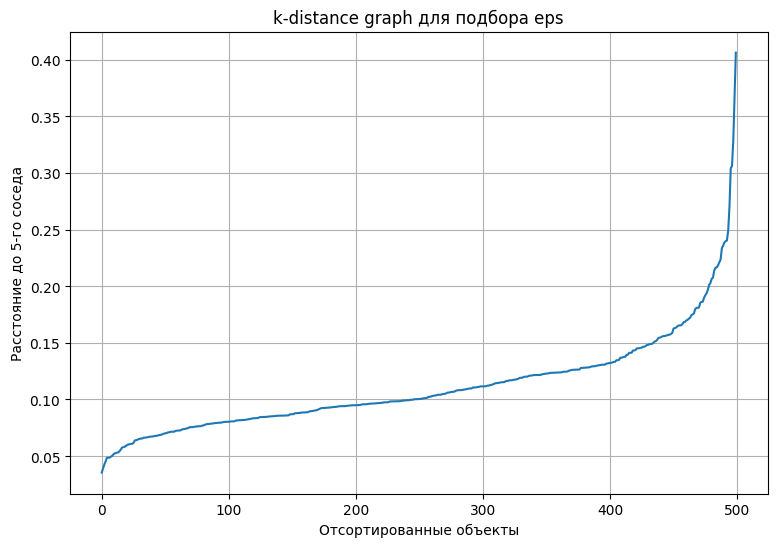

In [40]:
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=5)

neighbors_fit = neighbors.fit(X_c_scaled)

distances, indices = neighbors_fit.kneighbors(X_c_scaled)

distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 6))

plt.plot(distances)

plt.xlabel("Отсортированные объекты")
plt.ylabel("Расстояние до 5-го соседа")
plt.title("k-distance graph для подбора eps")

plt.show()

In [41]:
dbscan_c = DBSCAN(
    eps=0.30,
    min_samples=5
)

labels_dbscan_c = dbscan_c.fit_predict(X_c_scaled)

print("Уникальные метки:")
print(np.unique(labels_dbscan_c))

Уникальные метки:
[0 1]


In [42]:
unique_labels, counts = np.unique(
    labels_dbscan_c,
    return_counts=True
)

for label, count in zip(unique_labels, counts):
    if label == -1:
        print(f"Шум: {count} объектов")
    else:
        print(f"Кластер {label}: {count} объектов")

Кластер 0: 250 объектов
Кластер 1: 250 объектов


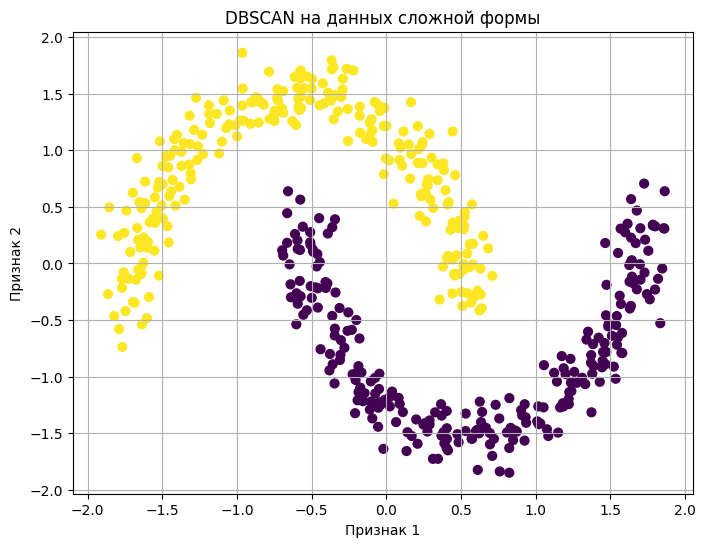

In [43]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_c_scaled[:, 0],
    X_c_scaled[:, 1],
    c=labels_dbscan_c,
    cmap="viridis",
    s=40
)

plt.xlabel("Признак 1")
plt.ylabel("Признак 2")
plt.title("DBSCAN на данных сложной формы")

plt.show()

In [44]:
mask_dbscan = labels_dbscan_c != -1

X_dbscan_clean = X_c_scaled[mask_dbscan]
labels_dbscan_clean = labels_dbscan_c[mask_dbscan]

if len(np.unique(labels_dbscan_clean)) >= 2:
    silhouette_dbscan = silhouette_score(
        X_dbscan_clean,
        labels_dbscan_clean
    )

    db_dbscan = davies_bouldin_score(
        X_dbscan_clean,
        labels_dbscan_clean
    )

    print(f"Silhouette DBSCAN: {silhouette_dbscan:.4f}")
    print(f"Davies-Bouldin DBSCAN: {db_dbscan:.4f}")
else:
    print("Недостаточно кластеров для расчёта метрик.")

Silhouette DBSCAN: 0.3836
Davies-Bouldin DBSCAN: 1.0241


In [45]:
hierarchical_c = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

labels_hierarchical_c = hierarchical_c.fit_predict(
    X_c_scaled
)

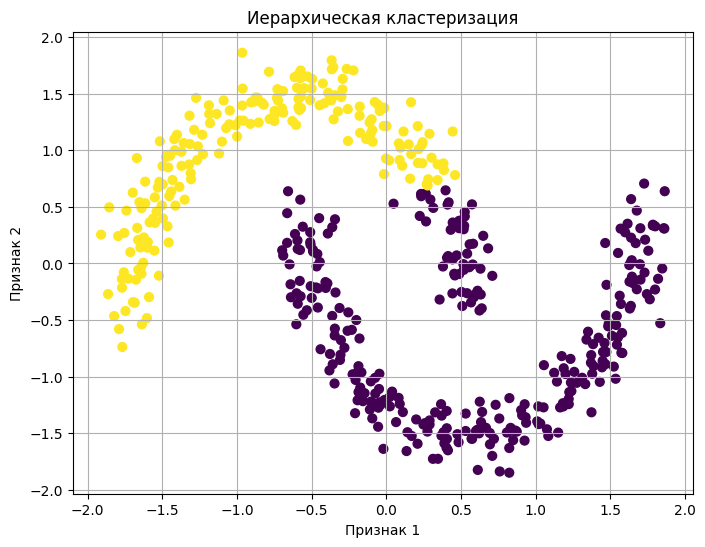

In [46]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_c_scaled[:, 0],
    X_c_scaled[:, 1],
    c=labels_hierarchical_c,
    cmap="viridis",
    s=40
)

plt.xlabel("Признак 1")
plt.ylabel("Признак 2")
plt.title("Иерархическая кластеризация")

plt.show()

In [47]:
sil_hierarchical = silhouette_score(
    X_c_scaled,
    labels_hierarchical_c
)

db_hierarchical = davies_bouldin_score(
    X_c_scaled,
    labels_hierarchical_c
)

print(f"Silhouette: {sil_hierarchical:.4f}")
print(f"Davies-Bouldin: {db_hierarchical:.4f}")

Silhouette: 0.4523
Davies-Bouldin: 0.8554


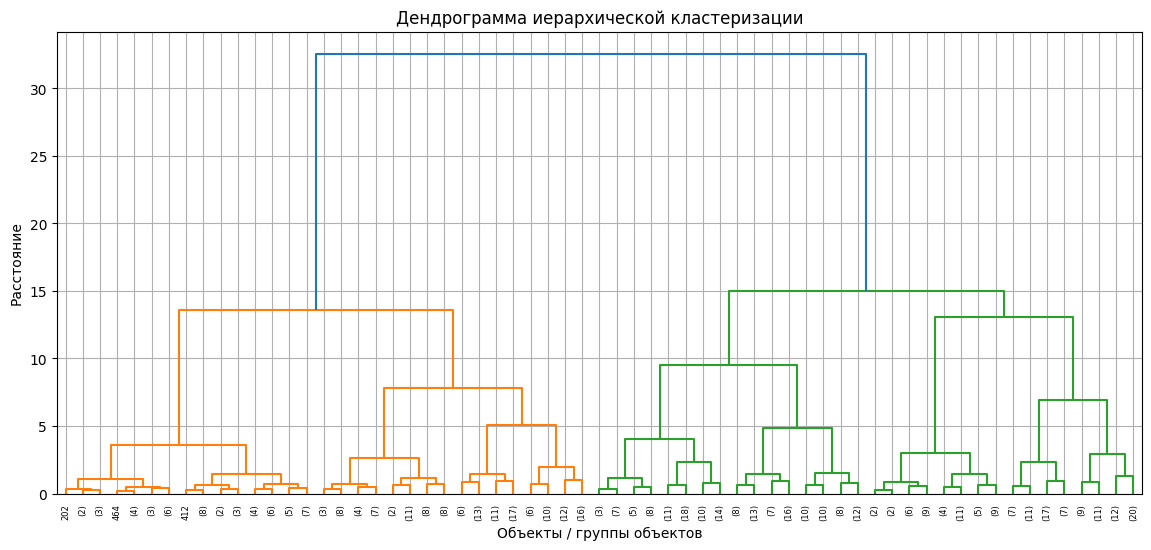

In [48]:
linkage_matrix = linkage(
    X_c_scaled,
    method="ward"
)

plt.figure(figsize=(14, 6))

dendrogram(
    linkage_matrix,
    truncate_mode="level",
    p=5
)

plt.xlabel("Объекты / группы объектов")
plt.ylabel("Расстояние")
plt.title("Дендрограмма иерархической кластеризации")

plt.show()

Дендрограмма показывает последовательность объединения объектов и групп объектов в процессе иерархической кластеризации. По вертикальной оси отображается расстояние, на котором происходит объединение. Чем выше происходит объединение двух ветвей, тем сильнее отличаются соответствующие группы. Дендрограмма позволяет рассматривать не только одно итоговое разбиение, но и различные уровни объединения данных.

In [49]:
comparison_c = pd.DataFrame({
    "Метод": [
        "K-Means",
        "DBSCAN",
        "Иерархическая кластеризация"
    ],
    "Silhouette": [
        sil_kmeans_c,
        silhouette_dbscan if len(np.unique(labels_dbscan_clean)) >= 2 else np.nan,
        sil_hierarchical
    ],
    "Davies-Bouldin": [
        db_kmeans_c,
        db_dbscan if len(np.unique(labels_dbscan_clean)) >= 2 else np.nan,
        db_hierarchical
    ]
})

display(comparison_c.round(4))

,Метод,Silhouette,Davies-Bouldin
0,K-Means,0.4932,0.8132
1,DBSCAN,0.3836,1.0241
2,Иерархическая кластеризация,0.4523,0.8554


In [50]:
from sklearn.metrics import adjusted_rand_score

ari_kmeans = adjusted_rand_score(
    y_true_c,
    labels_kmeans_c
)

ari_dbscan = adjusted_rand_score(
    y_true_c,
    labels_dbscan_c
)

ari_hierarchical = adjusted_rand_score(
    y_true_c,
    labels_hierarchical_c
)

comparison_ari = pd.DataFrame({
    "Метод": [
        "K-Means",
        "DBSCAN",
        "Иерархическая кластеризация"
    ],
    "Adjusted Rand Index": [
        ari_kmeans,
        ari_dbscan,
        ari_hierarchical
    ]
})

display(comparison_ari.round(4))

,Метод,Adjusted Rand Index
0,K-Means,0.4451
1,DBSCAN,1.0000
2,Иерархическая кластеризация,0.6265


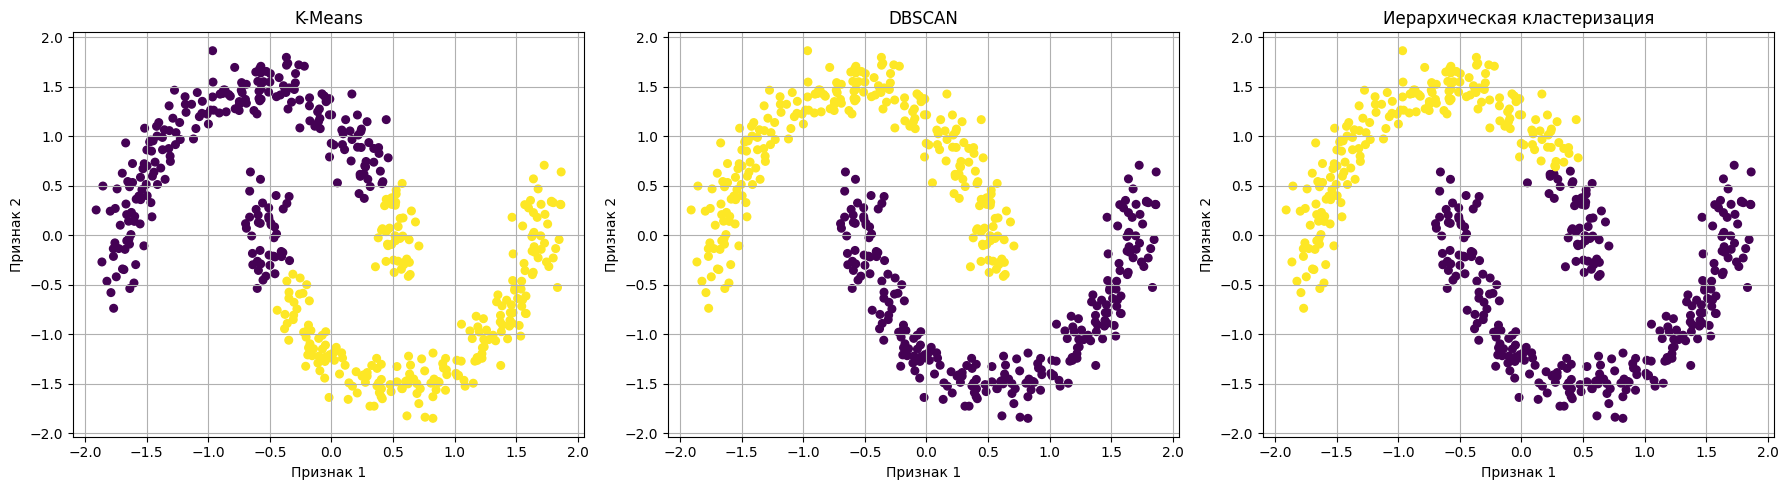

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(
    X_c_scaled[:, 0],
    X_c_scaled[:, 1],
    c=labels_kmeans_c,
    cmap="viridis",
    s=30
)
axes[0].set_title("K-Means")

axes[1].scatter(
    X_c_scaled[:, 0],
    X_c_scaled[:, 1],
    c=labels_dbscan_c,
    cmap="viridis",
    s=30
)
axes[1].set_title("DBSCAN")

axes[2].scatter(
    X_c_scaled[:, 0],
    X_c_scaled[:, 1],
    c=labels_hierarchical_c,
    cmap="viridis",
    s=30
)
axes[2].set_title("Иерархическая кластеризация")

for ax in axes:
    ax.set_xlabel("Признак 1")
    ax.set_ylabel("Признак 2")

plt.tight_layout()
plt.show()

В варианте C были рассмотрены данные сложной невыпуклой формы, представленные двумя полумесяцами. Для этих данных были применены K-Means, DBSCAN и иерархическая кластеризация. K-Means показал ограниченность метода, поскольку его механизм основан на расстоянии до центроидов и лучше подходит для компактных выпуклых кластеров. Иерархическая кластеризация с методом Ward также ориентируется на компактные группы и поэтому не полностью учитывает форму полумесяцев. DBSCAN способен учитывать пространственную плотность объектов и формировать кластеры произвольной формы, поэтому для рассматриваемых данных он является наиболее подходящим методом.

Параметры DBSCAN были подобраны не произвольно: для выбора eps был рассмотрен график k-расстояний. Параметр min_samples был установлен равным 5. Дополнительно результаты методов были сравнены с помощью коэффициента силуэта и индекса Davies-Bouldin. Для искусственного набора данных также был рассчитан Adjusted Rand Index, поскольку истинные метки кластеров были известны заранее.

В ходе практической работы были изучены и применены методы обучения без учителя для сегментации данных.

В варианте A метод K-Means был применён к данным о клиентах. Перед кластеризацией признаки были стандартизированы. Клиенты были разделены на 4 сегмента, после чего для каждого кластера были рассчитаны средние значения признаков: среднего чека, количества покупок в месяц, количества дней с последней покупки и доли покупок со скидкой. Это позволило дать содержательную характеристику каждому сегменту.

В варианте B количество кластеров определялось более обоснованно. Были построены графики метода локтя и коэффициента силуэта для значений k от 2 до 10. На основе полученных результатов было выбрано итоговое количество кластеров. После этого были построены профили сегментов и выполнена проверка устойчивости кластеризации с другим значением random_state.

В варианте C были рассмотрены данные сложной невыпуклой формы. На них были сравнены K-Means, DBSCAN и иерархическая кластеризация. Эксперимент показал, что K-Means имеет ограничения при работе с кластерами сложной формы, поскольку ориентируется на расстояние до центроидов. Иерархическая кластеризация также зависит от выбранного способа объединения объектов. DBSCAN оказался более подходящим для данных с формой полумесяцев, поскольку способен находить кластеры произвольной формы и выделять шумовые объекты.

Таким образом, выбор алгоритма кластеризации должен зависеть от структуры данных. K-Means удобен для компактных и хорошо разделённых сегментов, иерархическая кластеризация позволяет дополнительно анализировать структуру объединения объектов с помощью дендрограммы, а DBSCAN особенно полезен для кластеров сложной формы и данных с шумом.